### Loading Data From The PostgresSQL(Gold Layer)

In [353]:
from logging import logAsyncioTasks

import numpy as np
import pandas as pd
import seaborn as sns
from IPython.core.pylabtools import figsize
from sqlalchemy import create_engine, text, URL, create_engine
from matplotlib import pyplot as plt

In [354]:
# PostgreSQL credentials
username = "postgres"
password = "password"
host = "localhost"
port = 5432
database = "DeviceDock Data Warehouse"

# Creating Connection
connection_url = URL.create(
    "postgresql+psycopg2",
    username = username,
    password= password,
    host = host,
    port = port,
    database = database
)

engine = create_engine(connection_url)

print("Connected to Postgresql !!")

Connected to Postgresql !!


In [355]:
with engine.begin() as conn:
    print("================================")
    print("STARTED LOADING LAYERS......")
    print("================================")

    # 1. Load raw data into Bronze
    conn.execute(text("CALL bronze.load_bronze();"))
    print("Bronze Layer loaded successfully !!")

     # 2. Clean and standardize data in Silver
    conn.execute(text("CALL silver.load_silver();"))
    print("Silver Layer loaded successfully !!")

     # 3. Create business-ready data in Gold
    conn.execute(text("CALL gold.load_gold();"))
    print("Gold Layer loaded successfully !!")

print("================================")
print("ALL LAYERS LOADED!!")
print("================================")

STARTED LOADING LAYERS......
Bronze Layer loaded successfully !!
Silver Layer loaded successfully !!
Gold Layer loaded successfully !!
ALL LAYERS LOADED!!


In [356]:
# Loading tables

# 1.) Loading customer table from gold layer:
cust = pd.read_sql_query(
    """
    SELECT * FROM gold.dim_customers
    """, engine
)
print("customer data loaded !!")

# 2.) Loading products table from gold layer:
prod = pd.read_sql_query(
    """
    SELECT * FROM gold.dim_products
    """, engine
)
print("products data loaded !!")

# 3.) Loading stores table from gold layer:
stor = pd.read_sql_query(
    """
    SELECT * FROM gold.dim_stores
    """,engine
)
print("stores data loaded !!")

# 4.) Loading dates table from gold layer:
date = pd.read_sql_query(
    """
    SELECT * FROM gold.dim_dates
    """,engine
)
print("dates data loaded !!")

# 5.) Loading sales table from gold layer:
sale = pd.read_sql_query(
    """
    SELECT * FROM gold.fact_sales
    """,engine
)
print("sales data loaded !!")


customer data loaded !!
products data loaded !!
stores data loaded !!
dates data loaded !!
sales data loaded !!


### Cleaning Dataset

In [357]:
# Analyzing data
cust.head()

,customer_key,full_name,email_id,customer_segment,city,state,region,age,loyalty_tier,registration_date
0,C00001,Rohan Kapoor,rohan.kapoor1@gmail.com,Small Business,Guwahati,Assam,West,46.00,Standard,2025-05-03
1,C00002,Aadhya Bose,aadhya.bose2@example.in,Consumer,Ahmedabad,Gujarat,West,68.00,Platinum,2023-05-19
2,C00003,Nisha Iyer,nisha.iyer3@icloud.com,Consumer,Lucknow,Uttar Pradesh,North,19.00,Platinum,2025-04-15
3,C00004,Kiara Patel,kiara.patel4@hotmail.com,Student,Indore,Madhya Pradesh,Central,56.00,Gold,2020-07-12
4,C00005,Pooja Malhotra,pooja.malhotra5@outlook.com,Consumer,Bengaluru,Karnataka,South,60.00,Standard,2021-09-13


In [358]:
cust.shape

(4800, 10)

In [359]:
cust.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4800 entries, 0 to 4799
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_key       4800 non-null   object 
 1   full_name          4800 non-null   object 
 2   email_id           4800 non-null   object 
 3   customer_segment   4800 non-null   object 
 4   city               4800 non-null   object 
 5   state              4800 non-null   object 
 6   region             4800 non-null   object 
 7   age                4770 non-null   float64
 8   loyalty_tier       4725 non-null   object 
 9   registration_date  4701 non-null   object 
dtypes: float64(1), object(9)
memory usage: 375.1+ KB


In [360]:
cust.describe().round(2)

,age
count,"4,770.00"
mean,45.08
std,16.86
min,18.00
25%,31.00
50%,45.00
75%,59.00
max,204.00


In [361]:
cust["age"] = cust["age"].astype("Int64")

In [362]:
cust["registration_date"] = pd.to_datetime(cust["registration_date"])

In [363]:
cust["customer_key"].duplicated().sum()

np.int64(0)

In [364]:
cust.isnull().sum()

customer_key          0
full_name             0
email_id              0
customer_segment      0
city                  0
state                 0
region                0
age                  30
loyalty_tier         75
registration_date    99
dtype: int64

In [365]:
cust[cust["age"] >= 100]

,customer_key,full_name,email_id,customer_segment,city,state,region,age,loyalty_tier,registration_date
809,C00810,Saanvi Kulkarni,saanvi.kulkarni810@example.in,Consumer,Kochi,Kerala,South,150,Standard,2021-07-03
1137,C01137,Vivaan Joshi,vivaan_joshi1137@hotmail_com,Consumer,Gurugram,Haryana,North,150,Platinum,2025-07-14
1258,C01259,Neha Verma,N/A,Consumer,N/A,Gujarat,West,204,Silver,2019-10-26
1670,C01671,Ishaan Jain,ishaan.jain1671@hotmail.com,Content Creator,Mysuru,Karnataka,South,150,Silver,2024-06-12
1837,C01837,Aditya Bose,aditya.bose1837@hotmail.com,Small Business,Guwahati,Assam,East,150,Gold,2021-10-06
2059,C02060,Meera Verma,pooja.tripathi925@icloud.com,Consumer,Lucknow,Uttar Pradesh,North,150,Standard,2025-11-10
2933,C02934,Rahul Tripathi,rahul.tripathi2934@yahoo.com,Small Business,New Delhi,Delhi,North,204,Platinum,2019-03-07
3304,C03304,Reyansh Khan,reyansh.khan3304@icloud.com,Consumer,Surat,Gujarat,West,204,Standard,2021-05-14


In [366]:
cust.loc[cust["age"] > 100 ,"age"] = np.nan

In [367]:
cust.loc[cust["age"] > 100]

,customer_key,full_name,email_id,customer_segment,city,state,region,age,loyalty_tier,registration_date


In [368]:
for col in cust.columns:
    count = (cust[col] == "N/A").sum()

    if count >= 1:
        print(f"{col} :{count} N/A Values")

full_name :11 N/A Values
email_id :132 N/A Values
customer_segment :46 N/A Values
city :60 N/A Values
state :53 N/A Values
region :148 N/A Values


In [369]:
for col in ["customer_segment"]:
    mode_value = cust[col].mode()[0]
    print("-------------------------")
    print("column name:", col)
    print("mode value:" , mode_value)
    count = (cust[col] == "N/A").sum()
    if count >= 1:
        print(f"{col} :{count} N/A Values")
    print("-------------------------")
    cust[col] =cust[col].replace({'N/A': mode_value})


-------------------------
column name: customer_segment
mode value: Consumer
customer_segment :46 N/A Values
-------------------------


In [370]:
for col in ["city", "state", "region"]:
    cust.loc[cust[col] == "N/A", col] = np.nan

In [371]:
cust.isnull().sum()

customer_key           0
full_name              0
email_id               0
customer_segment       0
city                  60
state                 53
region               148
age                   38
loyalty_tier          75
registration_date     99
dtype: int64

In [372]:
cust["age"] = cust["age"].fillna(cust["age"].median())

In [373]:
age_skew = cust["age"].skew().round(2)
min_age = cust["age"].min()
max_age = cust["age"].max()

print("age skewness is:", age_skew)
print("minimum age is:", min_age)
print("maximum age is:", max_age)

age skewness is: -0.01
minimum age is: 18
maximum age is: 72


In [374]:
cust["loyalty_tier"] = cust["loyalty_tier"].fillna(cust["loyalty_tier"].mode()[0])

In [375]:
for col in ["full_name", "email_id"]:
    cust.loc[cust[col] == "N/A", col] = np.nan

In [376]:
cust.isnull().sum()

customer_key           0
full_name             11
email_id             132
customer_segment       0
city                  60
state                 53
region               148
age                    0
loyalty_tier           0
registration_date     99
dtype: int64

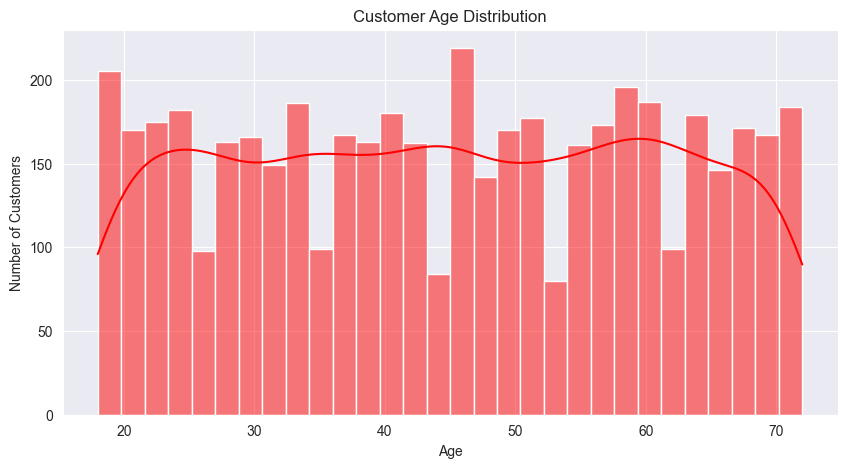

In [377]:
# Checking the age distribution
plt.figure(figsize = (10,5))
sns.histplot(data = cust["age"], kde = True, bins = 30, color = "red")
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.savefig("Customer Age Distribution")


1. **Age Distribution:** The highest customer count appears to be around the 45–46 age group, based on the tallest histogram bar.

2. **Skewness:** The age distribution appears relatively uniform across the observed age range, with no strong left or right skewness (skewness(-0.01)).

3. **Age Range:** Customer ages range approximately from 18 to 72 years in the displayed plot.

In [378]:
prod.head()

,product_key,product_name,brand_name,product_category,product_subcategory,product_specs,warranty_months,is_active,selling_price,product_cost,gross_profit,gross_profit_percent
0,P0001,Motorola Phone 16,Motorola,Smartphone,Premium Phone,4G; 256GB; 6GB RAM,24.00,Yes,"95,798.63","60,511.00","35,287.63",36.84
1,P0002,Motorola Iphone 4,Motorola,Smartphone,Android Phone,4G; 128GB; 8GB RAM,12.00,Yes,"10,123.48","8,616.97","1,506.51",14.88
2,P0003,Vivo Pixel Ultra,Vivo,Smartphone,Android Phone,4G; 512GB; 6GB RAM,6.00,Yes,"142,508.95","104,756.15","37,752.80",26.49
3,P0004,Nothing Nova 2025,Nothing,Smartphone,Premium Phone,5G; 256GB; 12GB RAM,12.00,Yes,"36,522.00","26,427.63","10,094.37",27.64
4,P0005,Samsung Nova Max,Samsung,Smartphone,5g Phone,4G; 128GB; 16GB RAM,36.00,Yes,"60,552.12","41,422.15","19,129.97",31.59


In [379]:
prod.shape

(162, 12)

In [380]:
prod.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   product_key           162 non-null    object 
 1   product_name          162 non-null    object 
 2   brand_name            162 non-null    object 
 3   product_category      162 non-null    object 
 4   product_subcategory   162 non-null    object 
 5   product_specs         162 non-null    object 
 6   warranty_months       160 non-null    float64
 7   is_active             162 non-null    object 
 8   selling_price         153 non-null    float64
 9   product_cost          160 non-null    float64
 10  gross_profit          151 non-null    float64
 11  gross_profit_percent  151 non-null    float64
dtypes: float64(5), object(7)
memory usage: 15.3+ KB


In [381]:
prod.describe().round(2)

,warranty_months,selling_price,product_cost,gross_profit,gross_profit_percent
count,160.00,153.00,160.00,151.00,151.00
mean,15.68,"37,319.64","27,351.08","9,906.27",25.45
std,8.38,"44,050.21","32,264.20","12,661.58",7.04
min,6.00,182.18,122.07,60.11,14.01
25%,12.00,"5,568.09","4,322.75","1,388.62",19.61
50%,12.00,"16,645.00","12,468.35","4,547.64",24.67
75%,24.00,"52,353.59","41,513.61","12,173.10",31.72
max,36.00,"204,176.17","149,746.73","54,429.44",37.98


In [382]:
prod["is_active"].value_counts()

is_active
Yes    155
No       7
Name: count, dtype: int64

In [383]:
for col in prod.columns:
    count = prod[col].isnull().sum()
    if count >=1:
        print(col, ":", prod[col].isnull().sum(), "null values")

warranty_months : 2 null values
selling_price : 9 null values
product_cost : 2 null values
gross_profit : 11 null values
gross_profit_percent : 11 null values


In [384]:
for col in ["warranty_months", "product_cost", "product_cost", "gross_profit", "gross_profit_percent"]:
    prod.loc[prod[col] == "N/A", col] = np.nan

In [385]:
prod.isnull().sum()

product_key              0
product_name             0
brand_name               0
product_category         0
product_subcategory      0
product_specs            0
warranty_months          2
is_active                0
selling_price            9
product_cost             2
gross_profit            11
gross_profit_percent    11
dtype: int64

In [386]:
cat_d = prod["product_category"].value_counts()

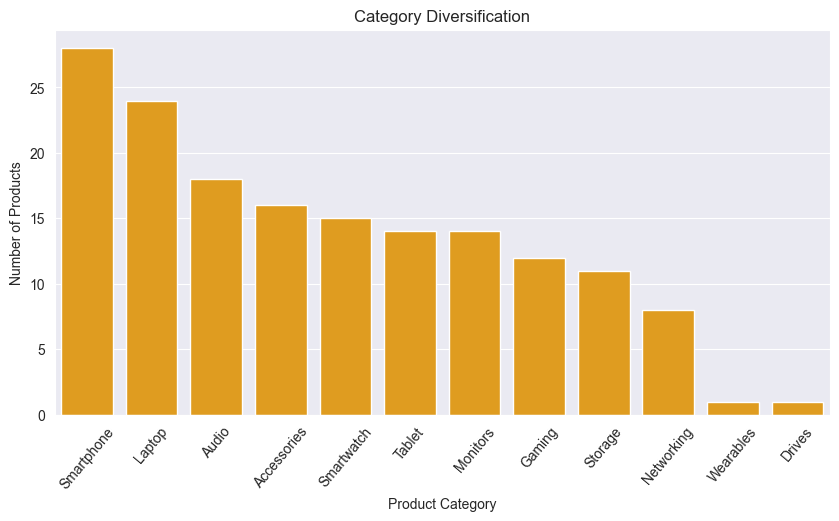

In [387]:
# Checking the Allocation among the various product categories
plt.figure(figsize = (10,5))
sns.barplot(data = cat_d, color = "orange")
plt.xticks(rotation = 50)
plt.title("Category Diversification")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.savefig("Category Diversification")

1.) The top 3 category having the maximum number of products are **Smartphone, Laptop, Audio**. <br>
2.) The bottom 3 category having the least number of products are **Drives, Wearables, Networking**.

In [388]:
date.head()

,date_key,calendar_date,year,month_number,month_name,quarter,day_name,is_weekend
0,20230101,2023-01-01,2023,1,January,1,Sunday,YES
1,20230102,2023-01-02,2023,1,January,1,Monday,NO
2,20230103,2023-01-03,2023,1,January,1,Tuesday,NO
3,20230104,2023-01-04,2023,1,January,1,Wednesday,NO
4,20230105,2023-01-05,2023,1,January,1,Thursday,NO


In [389]:
date.shape

(1096, 8)

In [390]:
date.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1096 entries, 0 to 1095
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   date_key       1096 non-null   object
 1   calendar_date  1093 non-null   object
 2   year           1093 non-null   object
 3   month_number   1093 non-null   object
 4   month_name     1093 non-null   object
 5   quarter        1093 non-null   object
 6   day_name       1093 non-null   object
 7   is_weekend     1096 non-null   object
dtypes: object(8)
memory usage: 68.6+ KB


In [391]:
date["date_key"].duplicated().sum()

np.int64(0)

In [392]:
for col in date.columns:
    count = date.loc[date[col] == "N/A", col].sum()
    if count >= 1:
        print("=======================")
        print(col)
        print("N/A values:", date.loc[date[col] == "N/A", col].sum())
        print("=======================")


In [393]:
date["calendar_date"] = pd.to_datetime(date["calendar_date"])

In [394]:
date.isnull().sum()

date_key         0
calendar_date    3
year             3
month_number     3
month_name       3
quarter          3
day_name         3
is_weekend       0
dtype: int64

In [395]:
date.dropna(subset= "calendar_date", inplace= True)

In [396]:
date.isnull().sum()

date_key         0
calendar_date    0
year             0
month_number     0
month_name       0
quarter          0
day_name         0
is_weekend       0
dtype: int64

In [397]:
date.shape

(1093, 8)

In [398]:
date.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1093 entries, 0 to 1095
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date_key       1093 non-null   object        
 1   calendar_date  1093 non-null   datetime64[ns]
 2   year           1093 non-null   object        
 3   month_number   1093 non-null   object        
 4   month_name     1093 non-null   object        
 5   quarter        1093 non-null   object        
 6   day_name       1093 non-null   object        
 7   is_weekend     1093 non-null   object        
dtypes: datetime64[ns](1), object(7)
memory usage: 76.9+ KB


In [399]:
date["month_name"].unique()

array(['January', 'June', 'December', 'November', 'February', 'March',
       'September', 'August', 'April', 'May', 'July', 'October'],
      dtype=object)

In [400]:
stor.head()

,store_key,store_name,channel_type,city,state,region,location_type,opening_date,store_status
0,S001,Techsquare Delhi Hub,Retail,Delhi,Delhi,North,Business Park,2018-01-03,Close
1,S002,Techsquare Noida Flagship,Retail,Noida,Uttar Pradesh,North,Express Outlet,2021-06-25,Open
2,S003,Techsquare Gurugram Express,B2b,Gurugram,Haryana,North,Business Park,2018-08-22,Open
3,S004,Techsquare Kanpur Mall,Retail,Kanpur,Uttar Pradesh,North,High Street,2023-07-28,N/A
4,S005,Techsquare Lucknow Mall,Retail,Lucknow,Uttar Pradesh,North,Mall,2021-02-14,Open


In [401]:
stor.shape

(28, 9)

In [402]:
stor.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   store_key      28 non-null     object
 1   store_name     28 non-null     object
 2   channel_type   28 non-null     object
 3   city           28 non-null     object
 4   state          28 non-null     object
 5   region         28 non-null     object
 6   location_type  28 non-null     object
 7   opening_date   27 non-null     object
 8   store_status   28 non-null     object
dtypes: object(9)
memory usage: 2.1+ KB


In [403]:
stor["store_key"].duplicated().sum()

np.int64(0)

In [404]:
stor.isnull().sum()

store_key        0
store_name       0
channel_type     0
city             0
state            0
region           0
location_type    0
opening_date     1
store_status     0
dtype: int64

In [405]:
for col in stor.columns:
    count = (stor[col] == "N/A").sum()
    if count >= 1:
        print(f"{col}: {count}  N/A values")

state: 1  N/A values
region: 2  N/A values
store_status: 4  N/A values


In [406]:
for col in stor.columns:
    stor.loc[stor[col] == 'N/A', col] = np.nan


In [407]:
stor.isnull().sum()

store_key        0
store_name       0
channel_type     0
city             0
state            1
region           2
location_type    0
opening_date     1
store_status     4
dtype: int64

In [408]:
stor["opening_date"] = pd.to_datetime(stor["opening_date"])

In [409]:
stor.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   store_key      28 non-null     object        
 1   store_name     28 non-null     object        
 2   channel_type   28 non-null     object        
 3   city           28 non-null     object        
 4   state          27 non-null     object        
 5   region         26 non-null     object        
 6   location_type  28 non-null     object        
 7   opening_date   27 non-null     datetime64[ns]
 8   store_status   24 non-null     object        
dtypes: datetime64[ns](1), object(8)
memory usage: 2.1+ KB


In [410]:
stor["region"].value_counts().reset_index(name = "total stores").sort_values(by = "total stores", ascending = False)

,region,total stores
0,North,8
1,West,7
2,South,7
3,Central,2
4,East,2


In [411]:
sale.head(5)

,sales_key,order_id,customer_key,product_key,store_key,date_key,order_date,payment_method,order_status,return_status,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
0,L00000001,ORD-25-0000001,C01805,P0016,S005,20251012,2025-10-12,Debit Card,Shipped,Not Returned,1.00,"15,750.00",0.00,"12,088.76",0.00,18.00,"18,585.00","12,088.76","6,496.24",34.95
1,L00000002,ORD-25-0000002,C00088,P0151,S021,20250926,2025-09-26,Wallet,Completed,N/A,1.00,"1,072.81",0.00,870.00,0.00,18.00,"1,265.92",870.00,395.92,31.28
2,L00000003,ORD-25-0000002,C00088,P0008,S021,20250926,2025-09-26,Wallet,Completed,Returned,1.00,"38,450.90",0.00,"29,289.31",0.00,18.00,"45,372.00","29,289.00","16,083.00",35.45
3,L00000004,ORD-23-0000003,C01258,P0018,S019,20230715,2023-07-15,Bank Transfer,Delivered,Not Returned,1.00,"86,086.64",18.00,"73,897.02",0.00,18.00,"83,297.43","73,897.00","9,400.43",11.29
4,L00000005,ORD-25-0000004,C00161,P0024,S006,20251225,2025-12-25,Wallet,Delivered,Not Returned,1.00,"28,031.00",18.00,"19,807.06",0.00,18.00,"27,123.00","19,807.00","7,316.00",26.97


In [412]:
sale.shape

(32420, 20)

In [413]:
sale.describe().round(2)

,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
count,"32,420.00","31,862.00","32,354.00","31,827.00","31,390.00","32,372.00","31,702.00","31,499.00","30,799.00","30,747.00"
mean,1.61,"67,848.19",10.88,"44,956.63","19,016.52",18.19,"72,996.93","57,655.60","16,956.19",-295.80
std,4.60,"530,524.81",10.27,"388,361.99","433,154.67",5.90,"416,909.78","426,630.59","584,486.90","19,445.43"
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"-9,999,553.18","-2,242,957.51"
25%,1.00,"5,644.74",5.00,"4,629.91",0.00,18.00,"8,513.72","6,174.94","1,661.94",20.58
50%,1.00,"19,740.07",10.00,"14,193.00",0.00,18.00,"30,144.82","20,615.00","7,041.44",27.93
75%,2.00,"58,935.52",15.00,"45,773.54",0.00,18.00,"77,284.76","57,441.82","20,767.96",35.04
max,99.00,"9,999,999.00",150.00,"9,999,999.00","9,999,999.00",180.00,"9,999,999.00","9,999,999.00","9,999,627.99",100.00


In [414]:
sale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32420 entries, 0 to 32419
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sales_key         32420 non-null  object 
 1   order_id          32420 non-null  object 
 2   customer_key      32420 non-null  object 
 3   product_key       32420 non-null  object 
 4   store_key         32420 non-null  object 
 5   date_key          32420 non-null  object 
 6   order_date        32275 non-null  object 
 7   payment_method    32420 non-null  object 
 8   order_status      32420 non-null  object 
 9   return_status     32420 non-null  object 
 10  quantity_sold     32420 non-null  float64
 11  selling_price     31862 non-null  float64
 12  discount_percent  32354 non-null  float64
 13  product_cost      31827 non-null  float64
 14  shipping_cost     31390 non-null  float64
 15  tax_percent       32372 non-null  float64
 16  sales_amount      31702 non-null  float6

In [415]:
sale["sales_key"].duplicated().sum()

np.int64(420)

In [416]:
sale["sales_key"].value_counts()

sales_key
L00011494    2
L00006346    2
L00009381    2
L00011251    2
L00013373    2
            ..
L00000012    1
L00000013    1
L00000014    1
L00000015    1
L00000016    1
Name: count, Length: 32000, dtype: int64

In [417]:
sale[sale["sales_key"] == "L00011494"]

,sales_key,order_id,customer_key,product_key,store_key,date_key,order_date,payment_method,order_status,return_status,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
11498,L00011494,ORD-25-0006149,C00002,P0078,S016,20250906,2025-09-06,Wallet,Delivered,Not Returned,1.00,"1,917.26",15.00,"1,559.00",0.00,18.00,"1,923.00","1,558.67",364.33,18.95
32213,L00011494,ORD-25-0006149,C00002,P0078,S016,20250906,2025-09-06,Wallet,Delivered,Not Returned,1.00,"1,917.26",15.00,"1,559.00",0.00,18.00,"1,923.00","1,558.67",364.33,18.95


In [418]:
sale[sale["sales_key"] == "L00011251"]

,sales_key,order_id,customer_key,product_key,store_key,date_key,order_date,payment_method,order_status,return_status,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
11255,L00011251,ORD-25-0006014,C02910,P0112,S025,20250815,2025-08-15,Cash On Delivery,Delivered,Not Returned,1.00,"70,700.03",15.00,"59,186.27",0.00,18.00,"70,912.13","59,186.27","11,725.86",16.54
32029,L00011251,ORD-25-0006014,C02910,P0112,S025,20250815,2025-08-15,Cash On Delivery,Delivered,Not Returned,1.00,"70,700.03",15.00,"59,186.27",0.00,18.00,"70,912.13","59,186.27","11,725.86",16.54


In [419]:
sale.drop_duplicates(subset= "sales_key", inplace= True)

In [420]:
sale.shape

(32000, 20)

In [421]:
# Update selling price from the product table
sale["selling_price"] = sale["product_key"].map(prod.set_index("product_key")["selling_price"])

# Updating product cost from the product table
sale["product_cost"] = sale["product_key"].map(prod.set_index("product_key")["product_cost"])

In [422]:
sale.isnull().sum()

sales_key              0
order_id               0
customer_key           0
product_key            0
store_key              0
date_key               0
order_date           122
payment_method         0
order_status           0
return_status          0
quantity_sold          0
selling_price       1417
discount_percent      64
product_cost         364
shipping_cost       1021
tax_percent           48
sales_amount         706
total_cost           906
profit_amount       1594
profit_percent      1644
dtype: int64

In [423]:
# Product keys present in sales but missing from the product table
missing_product_keys = sale.loc[
    ~sale["product_key"].isin(prod["product_key"]),
    "product_key"
].unique()

print("Mismatched product keys:", missing_product_keys)
print("Number of mismatched keys:", len(missing_product_keys))

Mismatched product keys: []
Number of mismatched keys: 0


In [424]:
prod.isnull().sum()

product_key              0
product_name             0
brand_name               0
product_category         0
product_subcategory      0
product_specs            0
warranty_months          2
is_active                0
selling_price            9
product_cost             2
gross_profit            11
gross_profit_percent    11
dtype: int64

In [425]:
print("selling price median :",prod["selling_price"].median())
print("product cost median :",prod["product_cost"].median())

selling price median : 16645.0
product cost median : 12468.35


In [426]:
# Replacing the missing selling price and the product cost in the products table;
prod["selling_price"].fillna(prod["selling_price"].median(), inplace= True)

prod["product_cost"].fillna(prod["product_cost"].median(), inplace= True)

C:\Users\Ranu Gupta\AppData\Local\Temp\ipykernel_53368\3907512383.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  prod["selling_price"].fillna(prod["selling_price"].median(), inplace= True)
C:\Users\Ranu Gupta\AppData\Local\Temp\ipykernel_53368\3907512383.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting valu

In [427]:
prod.isnull().sum()

product_key              0
product_name             0
brand_name               0
product_category         0
product_subcategory      0
product_specs            0
warranty_months          2
is_active                0
selling_price            0
product_cost             0
gross_profit            11
gross_profit_percent    11
dtype: int64

In [428]:
print("selling price median :",prod["selling_price"].median())
print("product cost median :",prod["product_cost"].median())

selling price median : 16645.0
product cost median : 12468.35


In [429]:
# Again Update selling price from the product table
sale["selling_price"] = sale["product_key"].map(prod.set_index("product_key")["selling_price"])

# Again Updating product cost from the product table
sale["product_cost"] = sale["product_key"].map(prod.set_index("product_key")["product_cost"])

In [430]:
sale.isnull().sum()

sales_key              0
order_id               0
customer_key           0
product_key            0
store_key              0
date_key               0
order_date           122
payment_method         0
order_status           0
return_status          0
quantity_sold          0
selling_price          0
discount_percent      64
product_cost           0
shipping_cost       1021
tax_percent           48
sales_amount         706
total_cost           906
profit_amount       1594
profit_percent      1644
dtype: int64

In [431]:
print("maximum discount_percent:" ,sale["discount_percent"].max())
print("minimum discount_percent:" ,sale["discount_percent"].min())
print("median discount_percent:" ,sale["discount_percent"].median())
print("mean discount_percent:" ,sale["discount_percent"].mean().round(2))

maximum discount_percent: 150.0
minimum discount_percent: 0.0
median discount_percent: 10.0
mean discount_percent: 10.89


In [432]:
sale["discount_percent"].describe().round(2)

count   31,936.00
mean        10.89
std         10.29
min          0.00
25%          5.00
50%         10.00
75%         15.00
max        150.00
Name: discount_percent, dtype: float64

In [433]:
sale[sale["discount_percent"] > 50].shape

(105, 20)

In [434]:
# Replacing the outliners in the discount percent with the median
sale.loc[sale["discount_percent"] > 50, "discount_percent"] = sale["discount_percent"].median()

In [435]:
# Replacing the null discount percent with 0
sale["discount_percent"].fillna(0, inplace= True)

C:\Users\Ranu Gupta\AppData\Local\Temp\ipykernel_53368\745342021.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sale["discount_percent"].fillna(0, inplace= True)


In [436]:
print("maximum shipping_cost:" ,sale["shipping_cost"].max())
print("minimum shipping_cost:" ,sale["shipping_cost"].min())
print("median shipping_cost:" ,sale["shipping_cost"].median())
print("mean shipping_cost:" ,sale["shipping_cost"].mean().round(2))

maximum shipping_cost: 9999999.0
minimum shipping_cost: 0.0
median shipping_cost: 0.0
mean shipping_cost: 19262.16


In [437]:
sale[sale["shipping_cost"] > 300]

,sales_key,order_id,customer_key,product_key,store_key,date_key,order_date,payment_method,order_status,return_status,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
586,L00000587,ORD-24-0000312,C00163,P0018,S007,20240911,2024-09-11,UPI,N/A,Not Returned,2.00,"95,961.92",5.00,"74,301.42","99,999.00",18.00,"205,172.00","147,851.40","57,320.60",27.94
1034,L00001035,ORD-23-0000545,C00015,P0015,S012,20230504,2023-05-04,Wallet,Cancelled,Not Returned,1.00,"129,927.91",15.00,"85,432.73","9,999,999.00",18.00,"115,552.87","85,124.17","30,428.70",26.33
1056,L00001057,ORD-25-0000559,C01698,P0088,S017,20250417,2025-04-17,UPI,Delivered,Not Returned,2.00,"1,311.53",15.00,878.92,"99,999.00",18.00,"2,557.43","1,801.00",756.43,29.58
1155,L00001156,ORD-23-0000609,C00793,P0097,S026,20230425,2023-04-25,Credit Card,Delivered,Not Returned,1.00,"3,226.00",12.00,"2,251.33","99,999.00",18.00,"3,243.57","2,243.90",999.67,30.82
2111,L00002111,ORD-25-0001120,C01240,P0014,S023,20250321,2025-03-21,UPI,Delivered,Not Returned,1.00,"9,751.00",5.00,"6,250.00","99,999.00",18.00,NaN,"6,237.04",NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31024,L00031023,ORD-25-0016707,C00050,P0015,S011,20250718,2025-07-18,UPI,Completed,Not Returned,1.00,"129,927.91",8.00,"85,432.73","9,999,999.00",18.00,"148,669.42","85,437.27","63,232.15",42.53
31642,L00031643,ORD-23-0017051,C03526,P0024,S010,20230315,2023-03-15,Cash On Delivery,Delivered,Pending Return,1.00,"27,249.43",5.00,"19,879.00","9,999,999.00",18.00,"29,052.09","20,346.30","8,705.79",29.97
31705,L00031706,ORD-23-0017081,C00061,P0007,S026,20230216,2023-02-16,Credit Card,Delivered,Not Returned,1.00,"16,645.00",18.00,"12,662.88","99,999.00",18.00,"16,359.00","12,647.79","3,711.21",22.69
31854,L00031855,ORD-23-0017162,C04009,P0078,S026,20230502,2023-05-02,Debit Card,Delivered,N/A,1.00,"1,868.00",12.00,"1,571.50","99,999.00",18.00,"1,973.14","1,557.00",416.14,21.09


In [438]:
# Replacing the wrong shipping cost values with median
sale.loc[sale["shipping_cost"] > 300, "shipping_cost"] = sale["shipping_cost"].median()

In [439]:
print("maximum shipping_cost:" ,sale["shipping_cost"].max())
print("minimum shipping_cost:" ,sale["shipping_cost"].min())
print("median shipping_cost:" ,sale["shipping_cost"].median())
print("mean shipping_cost:" ,sale["shipping_cost"].mean().round(2))

maximum shipping_cost: 199.0
minimum shipping_cost: 0.0
median shipping_cost: 0.0
mean shipping_cost: 13.64


In [440]:
sale.isnull().sum()

sales_key              0
order_id               0
customer_key           0
product_key            0
store_key              0
date_key               0
order_date           122
payment_method         0
order_status           0
return_status          0
quantity_sold          0
selling_price          0
discount_percent       0
product_cost           0
shipping_cost       1021
tax_percent           48
sales_amount         706
total_cost           906
profit_amount       1594
profit_percent      1644
dtype: int64

In [441]:
# Replacing the missing values in the shipping cost column with the mean(already handled with the outliers)
sale["shipping_cost"].fillna(sale["shipping_cost"].mean(), inplace= True)

C:\Users\Ranu Gupta\AppData\Local\Temp\ipykernel_53368\2636751007.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  sale["shipping_cost"].fillna(sale["shipping_cost"].mean(), inplace= True)


In [442]:
print("maximum tax_percent:" ,sale["tax_percent"].max())
print("minimum tax_percent:" ,sale["tax_percent"].min())
print("median tax_percent:" ,sale["tax_percent"].median())
print("mean tax_percent:" ,sale["tax_percent"].mean().round(2))

maximum tax_percent: 180.0
minimum tax_percent: 0.0
median tax_percent: 18.0
mean tax_percent: 18.19


In [443]:
sale[sale["tax_percent"] > 30].head(10)

,sales_key,order_id,customer_key,product_key,store_key,date_key,order_date,payment_method,order_status,return_status,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
1359,L00001359,ORD-24-0000715,C00052,P0120,S012,20240611,2024-06-11,Debit Card,Delivered,Not Returned,1.00,"2,595.00",15.00,"2,104.00",0.00,180.00,"2,678.00","2,127.00",551.00,20.58
1903,L00001903,ORD-25-0001007,C00178,P0002,S022,20251115,2025-11-15,UPI,Delivered,Not Returned,1.00,"10,123.48",8.00,"8,616.97",49.00,180.00,"10,747.96","8,675.33","2,072.63",19.28
2035,L00002035,ORD-25-0001076,C00176,P0061,S018,20250911,2025-09-11,Credit Card,Completed,Not Returned,1.00,"59,380.68",5.00,"49,977.21",0.00,180.00,"63,433.52","50,335.00","13,098.52",20.65
3539,L00003537,ORD-23-0001897,C02598,P0116,S023,20230301,2023-03-01,Net Banking,Completed,Not Returned,1.00,"5,534.00",8.00,"4,103.13",99.00,180.00,"5,670.00","4,173.00","1,497.00",26.40
3592,L00003590,ORD-23-0001922,C00536,P0040,S022,20230708,2023-07-08,Wallet,Pending,Not Returned,1.00,"87,134.82",15.00,"71,848.06",0.00,180.00,"85,361.00","73,209.06","12,151.94",14.24
4518,L00004516,ORD-23-0002437,C00272,P0116,S023,20231229,2023-12-29,Credit Card,Delivered,Returned,2.00,"5,534.00",25.00,"4,103.13",79.00,180.00,"9,788.60","8,107.44","1,681.16",17.17
5320,L00005315,ORD-23-0002857,C00130,P0037,S014,20230410,2023-04-10,Credit Card,Pending,Not Returned,2.00,"184,640.31",15.00,"131,152.00",0.00,180.00,"330,548.00","258,999.94","71,548.06",21.65
5695,L00005691,ORD-25-0003052,C00033,P0140,S014,20250731,2025-07-31,Credit Card,Delivered,Not Returned,3.00,"2,054.68",15.00,"1,680.00",0.00,180.00,"6,179.76","5,088.54","1,091.22",17.66
13739,L00013736,ORD-25-0007372,C01893,P0050,S021,20251213,2025-12-13,Debit Card,Completed,Not Returned,1.00,"16,645.00",25.00,"35,664.00",0.00,180.00,"45,193.78","35,129.92","10,063.86",22.27
14648,L00014645,ORD-24-0007870,C04338,P0129,S013,20240919,2024-09-18,Debit Card,N/A,Not Returned,5.00,"5,275.97",15.00,"4,482.85",0.00,180.00,"26,660.84","22,205.00","4,455.84",16.71


In [444]:
# Replacing the wrong tax percent values with median
sale.loc[sale["tax_percent"] > 30] = sale["tax_percent"].median()

In [445]:
print("maximum tax_percent:" ,sale["tax_percent"].max())
print("minimum tax_percent:" ,sale["tax_percent"].min())
print("median tax_percent:" ,sale["tax_percent"].median())
print("mean tax_percent:" ,sale["tax_percent"].mean().round(2))

maximum tax_percent: 28.0
minimum tax_percent: 0.0
median tax_percent: 18.0
mean tax_percent: 17.98


In [446]:
sale.isnull().sum()

sales_key              0
order_id               0
customer_key           0
product_key            0
store_key              0
date_key               0
order_date           122
payment_method         0
order_status           0
return_status          0
quantity_sold          0
selling_price          0
discount_percent       0
product_cost           0
shipping_cost          0
tax_percent           48
sales_amount         706
total_cost           905
profit_amount       1593
profit_percent      1643
dtype: int64

In [447]:
median_tax = sale.loc[
    sale["tax_percent"] <= 30,
    "tax_percent"
].median()

sale.loc[
    sale["tax_percent"] > 30,
    "tax_percent"
] = median_tax

In [448]:
# Recalculating all the dependent columns
# 1. Calculate sales amount
# Apply discount first, then tax, then add shipping
sale["sales_amount"] = (
    sale["quantity_sold"]
    * sale["selling_price"]
    * (1 - sale["discount_percent"] / 100)
    * (1 + sale["tax_percent"] / 100)
    + sale["shipping_cost"]
)

# 2. Calculate total cost
# Product cost for all units + shipping cost
sale["total_cost"] = (
    sale["quantity_sold"] * sale["product_cost"]
    + sale["shipping_cost"]
)

# 3. Calculate profit amount
sale["profit_amount"] = (
    sale["sales_amount"] - sale["total_cost"]
)

# 4. Calculate profit percentage
sale["profit_percent"] = (
    sale["profit_amount"]
    / sale["sales_amount"].replace(0, np.nan)
) * 100

# Round monetary values to 2 decimal places
sale[["sales_amount", "total_cost", "profit_amount"]] = (
    sale[["sales_amount", "total_cost", "profit_amount"]].round(2)
)

sale["profit_percent"] = sale["profit_percent"].round(2)

In [449]:
sale.isnull().sum()

sales_key             0
order_id              0
customer_key          0
product_key           0
store_key             0
date_key              0
order_date          122
payment_method        0
order_status          0
return_status         0
quantity_sold         0
selling_price         0
discount_percent      0
product_cost          0
shipping_cost         0
tax_percent          48
sales_amount         48
total_cost            0
profit_amount        48
profit_percent      176
dtype: int64

In [450]:
sale[sale["profit_percent"].isnull()]

,sales_key,order_id,customer_key,product_key,store_key,date_key,order_date,payment_method,order_status,return_status,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
10,L00000011,ORD-25-0000008,C02996,P0062,S007,20251005,2025-10-05,UPI,Returned,Not Returned,0.00,"94,156.91",0.00,"75,805.22",0.00,18.00,0.00,0.00,0.00,NaN
364,L00000365,ORD-25-0000194,C03935,P0004,S022,20251203,2025-12-04,Credit Card,Pending,Not Returned,0.00,"36,522.00",10.00,"26,427.63",0.00,18.00,0.00,0.00,0.00,NaN
820,L00000821,ORD-24-0000435,C00143,P0015,S023,20240920,2024-09-20,UPI,Delivered,Not Returned,1.00,"129,927.91",10.00,"85,432.73",0.00,NaN,NaN,"85,432.73",NaN,NaN
830,L00000831,ORD-25-0000440,C00839,P0075,S010,20251119,2025-11-19,Cash On Delivery,Completed,Not Returned,0.00,"1,517.00",0.00,"1,243.68",0.00,18.00,0.00,0.00,0.00,NaN
991,L00000992,ORD-24-0000524,C02487,P0129,S017,20240730,2024-07-30,EMI,Delivered,Returned,0.00,"5,275.97",0.00,"4,482.85",0.00,18.00,0.00,0.00,0.00,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30346,L00030345,ORD-25-0016336,C02887,P0018,S007,20250130,2025-01-30,EMI,Completed,Not Returned,1.00,"95,961.92",0.00,"74,301.42",0.00,NaN,NaN,"74,301.42",NaN,NaN
30637,L00030636,ORD-25-0016496,C00416,P0001,S016,20250429,2025-04-29,EMI,Delivered,Not Returned,1.00,"95,798.63",0.00,"60,511.00",0.00,NaN,NaN,"60,511.00",NaN,NaN
31269,L00031268,ORD-23-0016836,C02221,P0095,S002,20230810,2023-08-10,UPI,Delivered,Not Returned,0.00,"2,713.58",15.00,"2,093.00",0.00,18.00,0.00,0.00,0.00,NaN
31720,L00031721,ORD-23-0017090,C00706,P0091,S009,20230807,2023-07-08,Net Banking,Delivered,Not Returned,0.00,"55,554.00",5.00,"45,200.33",0.00,18.00,0.00,0.00,0.00,NaN


In [451]:
sale[sale["quantity_sold"] == 0].shape

(148, 20)

In [452]:
sale.loc[sale["quantity_sold"] == 0, "quantity_sold"] = np.nan

In [453]:
# Removing the rows where the quantity sold is 0
sale.dropna(subset= "quantity_sold", inplace= True)

In [454]:
sale.shape

(31852, 20)

In [455]:
sale.isnull().sum()

sales_key             0
order_id              0
customer_key          0
product_key           0
store_key             0
date_key              0
order_date          119
payment_method        0
order_status          0
return_status         0
quantity_sold         0
selling_price         0
discount_percent      0
product_cost          0
shipping_cost         0
tax_percent          48
sales_amount         48
total_cost            0
profit_amount        48
profit_percent       48
dtype: int64

In [456]:
sale.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31852 entries, 0 to 31999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sales_key         31852 non-null  object 
 1   order_id          31852 non-null  object 
 2   customer_key      31852 non-null  object 
 3   product_key       31852 non-null  object 
 4   store_key         31852 non-null  object 
 5   date_key          31852 non-null  object 
 6   order_date        31733 non-null  object 
 7   payment_method    31852 non-null  object 
 8   order_status      31852 non-null  object 
 9   return_status     31852 non-null  object 
 10  quantity_sold     31852 non-null  float64
 11  selling_price     31852 non-null  float64
 12  discount_percent  31852 non-null  float64
 13  product_cost      31852 non-null  float64
 14  shipping_cost     31852 non-null  float64
 15  tax_percent       31804 non-null  float64
 16  sales_amount      31804 non-null  float64
 17

In [457]:
sale["order_date"] = pd.to_datetime(sale["order_date"])

In [458]:
sale.describe().round(2)

,order_date,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
count,31733,"31,852.00","31,852.00","31,852.00","31,852.00","31,852.00","31,804.00","31,804.00","31,852.00","31,804.00","31,804.00"
mean,2024-08-10 10:47:11.399489280,1.65,"39,893.90",10.47,"29,691.14",13.66,17.98,"64,707.77","45,625.90","19,071.32",25.36
min,1970-01-01 00:00:00.000000018,1.00,18.00,0.00,18.00,0.00,0.00,150.48,122.07,"-3,895,485.16",-544.09
25%,2023-12-05 00:00:00,1.00,"7,250.88",5.00,"4,630.69",0.00,18.00,"9,348.04","6,250.00","2,000.18",22.75
50%,2024-10-13 00:00:00,1.00,"16,645.00",10.00,"13,097.48",0.00,18.00,"30,083.96","20,339.27","8,005.42",29.56
75%,2025-06-14 00:00:00,2.00,"57,643.00",15.00,"45,206.59",0.00,18.00,"76,208.77","57,354.35","22,495.30",36.30
max,2026-12-28 00:00:00,99.00,"204,176.17",30.00,"149,746.73",199.00,28.00,"16,776,193.10","14,824,926.27","5,961,429.25",98.53
std,NaN,4.67,"45,514.55",7.39,"33,519.01",37.36,0.88,"287,490.05","208,986.26","94,951.92",43.32


In [459]:
for col in sale.columns:
    count = (sale[col] == 'N/A').sum()

    if count > 0:
        print(f"{col}: {count} N/A values")

order_status: 254 N/A values
return_status: 1004 N/A values


In [460]:
for col in ["order_status", "return_status"]:
    sale.loc[sale[col] == "N/A", col] = sale[col].mode()[0]

In [461]:
# Create a lookup from the date dimension
date_lookup = date.set_index("date_key")["calendar_date"]

# Fill missing order dates using the matching date_key
sale["order_date"] = sale["order_date"].fillna(
    sale["date_key"].map(date_lookup)
)

In [462]:
sale.isnull().sum()

sales_key            0
order_id             0
customer_key         0
product_key          0
store_key            0
date_key             0
order_date           0
payment_method       0
order_status         0
return_status        0
quantity_sold        0
selling_price        0
discount_percent     0
product_cost         0
shipping_cost        0
tax_percent         48
sales_amount        48
total_cost           0
profit_amount       48
profit_percent      48
dtype: int64

In [463]:
date.isnull().sum()

date_key         0
calendar_date    0
year             0
month_number     0
month_name       0
quarter          0
day_name         0
is_weekend       0
dtype: int64

In [464]:
for col in date.columns:
    count = (date[col] == 'N/A').sum()

    if count > 0:
        print(f"{col}: {count} N/A values")

In [465]:
prod.isnull().sum()

product_key              0
product_name             0
brand_name               0
product_category         0
product_subcategory      0
product_specs            0
warranty_months          2
is_active                0
selling_price            0
product_cost             0
gross_profit            11
gross_profit_percent    11
dtype: int64

In [466]:
prod["gross_profit"] = prod["selling_price"] - prod["product_cost"]

In [467]:
prod["gross_profit_percent"] = ((prod["gross_profit"]/prod["selling_price"])*100).round(2)

In [468]:
prod.isnull().sum()

product_key             0
product_name            0
brand_name              0
product_category        0
product_subcategory     0
product_specs           0
warranty_months         2
is_active               0
selling_price           0
product_cost            0
gross_profit            0
gross_profit_percent    0
dtype: int64

In [469]:
for col in prod.columns:
    count = (prod[col] == 'N/A').sum()

    if count > 0:
        print(f"{col}: {count} N/A values")

product_name: 3 N/A values
product_subcategory: 3 N/A values
product_specs: 3 N/A values


In [470]:
for col in stor.columns:
    count = (stor[col] == 'N/A').sum()

    if count > 0:
        print(f"{col}: {count} N/A values")

In [471]:
stor.isnull().sum()

store_key        0
store_name       0
channel_type     0
city             0
state            1
region           2
location_type    0
opening_date     1
store_status     4
dtype: int64

In [472]:
for col in cust.columns:
    count = (cust[col] == 'N/A').sum()

    if count > 0:
        print(f"{col}: {count} N/A values")

In [473]:
# Not removing or replacing the missing values from the customers and stores tables because it can led to misleading further analysis.
cust.isnull().sum()

customer_key           0
full_name             11
email_id             132
customer_segment       0
city                  60
state                 53
region               148
age                    0
loyalty_tier           0
registration_date     99
dtype: int64

In [474]:
# Missing values
print("Missing values:\n", sale.isnull().sum())

# Duplicate sales keys
print("Duplicate sales keys:", sale["sales_key"].duplicated().sum())

# Invalid quantities
print("Zero or negative quantities:",
      (sale["quantity_sold"] <= 0).sum())

Missing values:
 sales_key            0
order_id             0
customer_key         0
product_key          0
store_key            0
date_key             0
order_date           0
payment_method       0
order_status         0
return_status        0
quantity_sold        0
selling_price        0
discount_percent     0
product_cost         0
shipping_cost        0
tax_percent         48
sales_amount        48
total_cost           0
profit_amount       48
profit_percent      48
dtype: int64
Duplicate sales keys: 41
Zero or negative quantities: 0


In [475]:
sale["sales_key"].value_counts()

sales_key
18.00         42
 L00032000     1
 L00000001     1
 L00000002     1
 L00031984     1
              ..
 L00000016     1
 L00000017     1
 L00000018     1
 L00000019     1
 L00000004     1
Name: count, Length: 31811, dtype: int64

In [476]:
sale[sale["sales_key"] == 18.0 ]

,sales_key,order_id,customer_key,product_key,store_key,date_key,order_date,payment_method,order_status,return_status,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
1359,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17
1903,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17
2035,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17
3539,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17
3592,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17
4518,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17
5320,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17
5695,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17
13739,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17
14648,18.00,18.00,18.00,18.00,18.00,18.00,1970-01-01 00:00:00.000000018,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,331.50,342.00,-10.50,-3.17


In [477]:
sale.loc[sale["sales_key"] == 18.0, "sales_key"] = np.nan

In [478]:
sale.dropna(subset = "sales_key", inplace= True)

In [479]:
sale.shape

(31810, 20)

In [480]:
# Missing values
print("Missing values:\n", sale.isnull().sum())

# Duplicate sales keys
print("Duplicate sales keys:", sale["sales_key"].duplicated().sum())

# Invalid quantities
print("Zero or negative quantities:",
      (sale["quantity_sold"] <= 0).sum())


Missing values:
 sales_key            0
order_id             0
customer_key         0
product_key          0
store_key            0
date_key             0
order_date           0
payment_method       0
order_status         0
return_status        0
quantity_sold        0
selling_price        0
discount_percent     0
product_cost         0
shipping_cost        0
tax_percent         48
sales_amount        48
total_cost           0
profit_amount       48
profit_percent      48
dtype: int64
Duplicate sales keys: 0
Zero or negative quantities: 0


### Exploratory Data Analysis

#### **Exploring Revenue Seasonality Across Months**

In [481]:
date_sale = pd.merge(sale, date, on = "date_key", how = "inner")

In [482]:
months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

date_sale["month_name"] = pd.Categorical(
    date_sale["month_name"],
    categories=months,
    ordered=True
)
avg_rev_mon = date_sale.groupby("month_name", observed = False)["sales_amount"].mean().round(2).reset_index(name = "avg revenue")

In [483]:
avg_rev_mon

,month_name,avg revenue
0,January,"67,638.61"
1,February,"62,314.58"
2,March,"76,634.69"
3,April,"77,107.68"
4,May,"64,700.27"
5,June,"62,990.90"
6,July,"61,596.26"
7,August,"56,203.26"
8,September,"62,788.10"
9,October,"63,829.66"


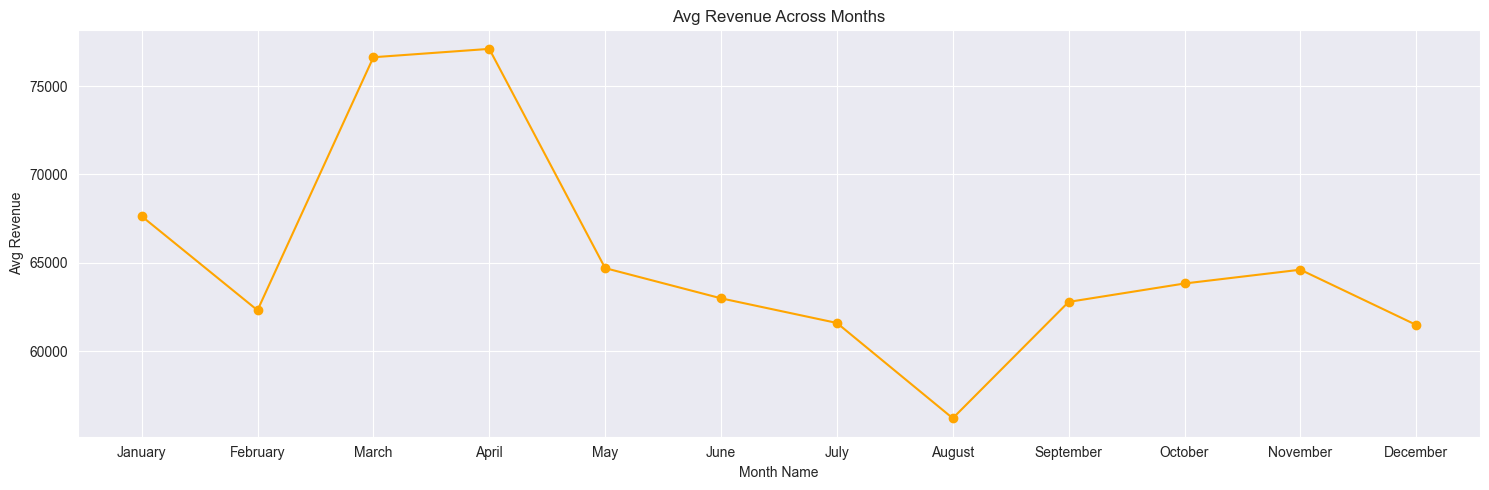

In [484]:
plt.figure(figsize= (15,5))
plt.plot(avg_rev_mon["month_name"], avg_rev_mon["avg revenue"], color = "orange", marker = "o")
plt.xlabel("Month Name")
plt.ylabel("Avg Revenue")
plt.title("Avg Revenue Across Months")

plt.tight_layout()
plt.savefig("Avg Revenue Across Months")

- **Highest Revenue Months:** March and April record the highest average revenue, with April slightly outperforming March.

- **Lowest Revenue Month:** August records the lowest average revenue. From September onwards, average revenue gradually increases until November, followed by a slight decline in December.

- **Monthly Revenue Fluctuations:** Average revenue drops sharply from January to February, followed by a significant increase in March and April. It then declines consistently from April through August.

- **Further Analysis:** To investigate these trends further, we can analyse the total number of orders placed each month to determine whether revenue fluctuations are driven by changes in order volume.

In [485]:
months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

date_sale["month_name"] = pd.Categorical(
    date_sale["month_name"],
    categories=months,
    ordered=True
)

total_odr_mon = date_sale.groupby("month_name", observed = False)["sales_key"].count().reset_index(name = "Total Orders")

In [486]:
total_odr_mon

,month_name,Total Orders
0,January,2325
1,February,1930
2,March,2126
3,April,2427
4,May,2550
5,June,2491
6,July,2444
7,August,2559
8,September,2339
9,October,3248


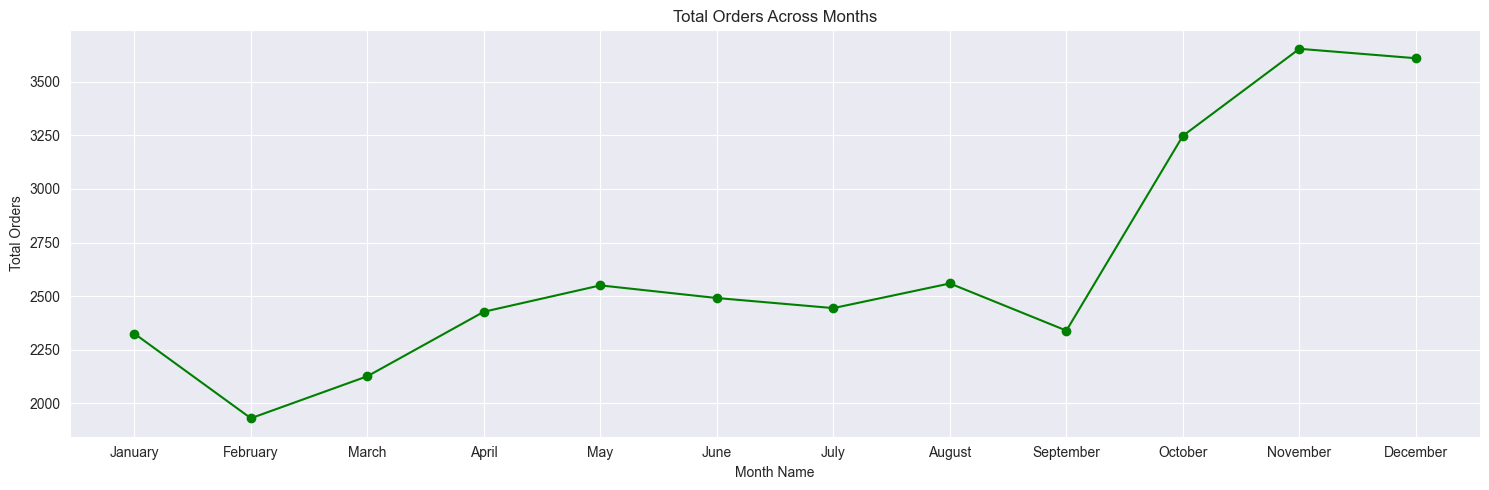

In [487]:
plt.figure(figsize= (15,5))
plt.plot(total_odr_mon["month_name"], total_odr_mon["Total Orders"], color = "green", marker = "o")
plt.xlabel("Month Name")
plt.ylabel("Total Orders")
plt.title("Total Orders Across Months")

plt.tight_layout()
plt.savefig("Total Orders Across Months")


- **Monthly Order Trends:** February records the lowest number of orders. Order volume gradually increases from February to May, followed by minor fluctuations until September. A sharp increase is observed from October onwards, with November recording the highest order volume, followed by a slight decline in December.

- **Average Revenue vs Order Volume:** March and April record the highest average revenue despite having fewer orders compared to October and November. This could indicate a higher average revenue per order during these months.

- **Overall Business Performance:** Analysing average revenue alongside total order volume provides a more complete picture of monthly business performance. Relying solely on average revenue can be misleading, as revenue fluctuations may be driven by changes in order volume or revenue generated per order.

#### **Which product categories and subcategories drive the most business value ?**

In [488]:
pro_sale = pd.merge(prod, sale, on = "product_key", how = "inner")

In [489]:
cat_sale = pro_sale.groupby("product_category")["sales_amount"].mean().round(2).reset_index(name = "avg revenue").sort_values(by = "avg revenue" , ascending = False)

In [490]:
cat_sale

,product_category,avg revenue
4,Laptop,"147,300.80"
7,Smartphone,"95,074.01"
10,Tablet,"87,030.33"
2,Drives,"73,656.33"
5,Monitors,"44,553.79"
3,Gaming,"26,741.79"
11,Wearables,"25,669.54"
8,Smartwatch,"24,532.47"
9,Storage,"20,751.44"
1,Audio,"18,207.26"


In [491]:
cat_odr = pro_sale.groupby("product_category")["sales_amount"].count().reset_index(name = "total orders").sort_values(by = "total orders" , ascending = False)

In [492]:
cat_odr

,product_category,total orders
7,Smartphone,7673
4,Laptop,5002
1,Audio,4094
0,Accessories,3798
8,Smartwatch,2753
10,Tablet,2549
5,Monitors,1931
9,Storage,1311
3,Gaming,1299
6,Networking,989


In [493]:
subcat_sale = pro_sale.groupby("product_subcategory")["sales_amount"].mean().round(2).reset_index(name = "avg revenue").sort_values(by = "avg revenue" , ascending = False).head(10)

In [494]:
subcat_sale

,product_subcategory,avg revenue
18,Gaming Laptop,"169,535.75"
32,Ultrabook,"165,669.32"
10,Consumer Laptop,"143,939.79"
3,Android Phone,"118,417.23"
4,Android Tablet,"111,922.63"
28,Premium Phone,"110,992.92"
6,Business Laptop,"106,923.26"
1,5g Phone,"105,602.45"
0,4k Monitor,"71,761.24"
29,Premium Tablet,"71,271.27"


In [495]:
subcat_odr = pro_sale.groupby("product_subcategory")["sales_amount"].count().reset_index(name = "total orders").sort_values(by = "total orders" , ascending = False).head(10)

In [496]:
subcat_odr

,product_subcategory,total orders
1,5g Phone,2456
35,Wired Headphones,2400
28,Premium Phone,2245
5,Budget Phone,1726
21,Keyboard,1647
18,Gaming Laptop,1460
30,Premium Watch,1255
3,Android Phone,1246
4,Android Tablet,1207
32,Ultrabook,1191


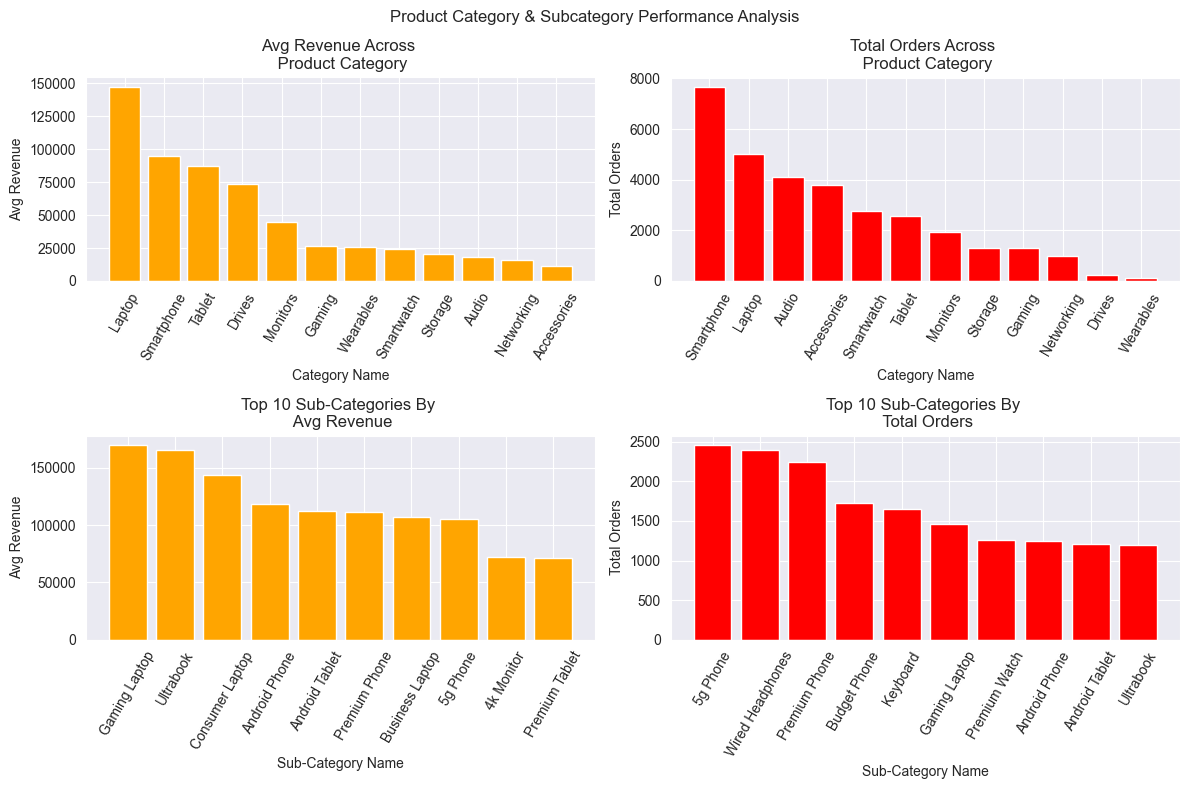

In [497]:
figure, ax = plt.subplots(2,2, figsize =(12,8))

#Chart1
ax[0,0].bar(cat_sale["product_category"], cat_sale["avg revenue"], color = "orange")
ax[0,0].tick_params(axis = "x", rotation = 60)
ax[0,0].set_xlabel("Category Name")
ax[0,0].set_ylabel("Avg Revenue")
ax[0,0].set_title("Avg Revenue Across \n Product Category")

#Chart2
ax[0,1].bar(cat_odr["product_category"], cat_odr["total orders"], color = "red")
ax[0,1].tick_params(axis = "x", rotation = 60)
ax[0,1].set_xlabel("Category Name")
ax[0,1].set_ylabel("Total Orders")
ax[0,1].set_title("Total Orders Across \n Product Category")

#Chart3
ax[1,0].bar(subcat_sale["product_subcategory"], subcat_sale["avg revenue"], color = "orange")
ax[1,0].tick_params(axis = "x", rotation = 60)
ax[1,0].set_xlabel("Sub-Category Name")
ax[1,0].set_ylabel("Avg Revenue")
ax[1,0].set_title("Top 10 Sub-Categories By \n Avg Revenue")

#Chart4
ax[1,1].bar(subcat_odr["product_subcategory"], subcat_odr["total orders"], color = "red")
ax[1,1].tick_params(axis = "x", rotation = 60)
ax[1,1].set_xlabel("Sub-Category Name")
ax[1,1].set_ylabel("Total Orders")
ax[1,1].set_title("Top 10 Sub-Categories By \n Total Orders")

plt.suptitle("Product Category & Subcategory Performance Analysis")
plt.tight_layout()
plt.savefig("Product Category & Subcategory Performance Analysis")

- **Revenue Performance Across Categories:** Laptops generate the highest average revenue, followed by Smartphones and Tablets. Networking and Accessories are the lowest average revenue-generating categories.

- **Order Volume Across Categories:** Smartphones account for the highest number of orders, followed by Laptops and Audio. Wearables and Drives record the lowest order volumes. Interestingly, Audio ranks among the top three categories in order volume despite having relatively low average revenue, suggesting a lower average revenue contribution per transaction.

- **Top-Performing Subcategories:** Gaming Laptops, Ultrabooks, and Consumer Laptops are the top three subcategories in terms of average revenue. In contrast, 5G Phones, Wired Headphones, and Premium Phones lead in total order volume.

- **Overall Business Observation:** Comparing average revenue and order volume highlights differences in purchasing patterns across product categories. Some categories generate higher average revenue with fewer orders, while others achieve higher order volumes despite relatively lower average revenue.

**How do different customer characteristics and geographical factors influence overall business performance and revenue generation?**

In [498]:
cust.head(1)

,customer_key,full_name,email_id,customer_segment,city,state,region,age,loyalty_tier,registration_date
0,C00001,Rohan Kapoor,rohan.kapoor1@gmail.com,Small Business,Guwahati,Assam,West,46,Standard,2025-05-03


In [499]:
print("min age:" , cust["age"].min())
print("max age:",cust["age"].max())
print("mean age:" , cust["age"].mean().round(2))

min age: 18
max age: 72
mean age: 44.87


In [500]:
# Defining age group boundaries
bins = [17, 28, 40, cust["age"].max()]

# Assigning labels to each age group
labels = ["Young", "Millennial", "Mature Adults"]

# Creating a new age_group column using pd.cut()
cust["age_group"] = pd.cut(
    cust["age"],
    bins=bins,
    labels=labels
)

In [501]:
cust.head()

,customer_key,full_name,email_id,customer_segment,city,state,region,age,loyalty_tier,registration_date,age_group
0,C00001,Rohan Kapoor,rohan.kapoor1@gmail.com,Small Business,Guwahati,Assam,West,46,Standard,2025-05-03,Mature Adults
1,C00002,Aadhya Bose,aadhya.bose2@example.in,Consumer,Ahmedabad,Gujarat,West,68,Platinum,2023-05-19,Mature Adults
2,C00003,Nisha Iyer,nisha.iyer3@icloud.com,Consumer,Lucknow,Uttar Pradesh,North,19,Platinum,2025-04-15,Young
3,C00004,Kiara Patel,kiara.patel4@hotmail.com,Student,Indore,Madhya Pradesh,Central,56,Gold,2020-07-12,Mature Adults
4,C00005,Pooja Malhotra,pooja.malhotra5@outlook.com,Consumer,Bengaluru,Karnataka,South,60,Standard,2021-09-13,Mature Adults


In [502]:
cust_sale = pd.merge(cust, sale, on = "customer_key", how = "inner")

In [503]:
pd.options.display.float_format = '{:,.2f}'.format
age_grp_sale = cust_sale.groupby("age_group")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending = False)

C:\Users\Ranu Gupta\AppData\Local\Temp\ipykernel_53368\3007914725.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_grp_sale = cust_sale.groupby("age_group")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending = False)


In [504]:
age_grp_sale

,age_group,total revenue
2,Mature Adults,"1,208,322,293.01"
0,Young,"435,750,180.34"
1,Millennial,"413,879,671.97"


In [505]:
pd.options.display.float_format = '{:,.2f}'.format
tier_sale = cust_sale.groupby("loyalty_tier")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending = False)

In [506]:
tier_sale

,loyalty_tier,total revenue
3,Standard,"997,843,415.56"
2,Silver,"415,580,798.01"
0,Gold,"325,717,908.21"
1,Platinum,"231,827,839.89"
4,VIP,"86,982,183.65"


In [507]:
pd.options.display.float_format = '{:,.2f}'.format
segment_sales = cust_sale.groupby("customer_segment")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending = False)

In [508]:
segment_sales

,customer_segment,total revenue
1,Consumer,"1,140,182,836.14"
5,Small Business,"307,244,791.91"
6,Student,"272,557,648.06"
2,Content Creator,"186,562,381.10"
3,Enterprise,"124,636,376.31"
4,Large Business,"14,954,914.53"
0,Campus,"11,813,197.27"


In [509]:
pd.options.display.float_format = '{:,.2f}'.format
cust_state_sale = cust_sale.groupby("state")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending = False).head(10)

In [510]:
cust_state_sale

,state,total revenue
14,Uttar Pradesh,"258,264,017.24"
9,Maharashtra,"226,829,391.68"
3,Delhi,"167,341,326.69"
8,Madhya Pradesh,"166,997,412.38"
6,Karnataka,"148,310,548.81"
4,Gujarat,"139,589,432.27"
12,Tamil Nadu,"114,523,052.35"
0,Assam,"109,577,978.04"
15,Uttarakhand,"107,451,072.57"
2,Chandigarh,"100,460,983.52"


In [511]:
corr_age_sale = np.corrcoef(cust_sale["age"], cust_sale["sales_amount"])
print(corr_age_sale)

[[ 1. nan]
 [nan nan]]


In [512]:
pd.options.display.float_format = '{:,.2f}'.format
region_sale = cust_sale.groupby("region")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending = False)
region_sale

,region,total revenue
2,North,"710,340,495.31"
3,South,"415,043,573.99"
4,West,"342,195,317.76"
1,East,"295,402,935.42"
0,Central,"236,817,393.87"


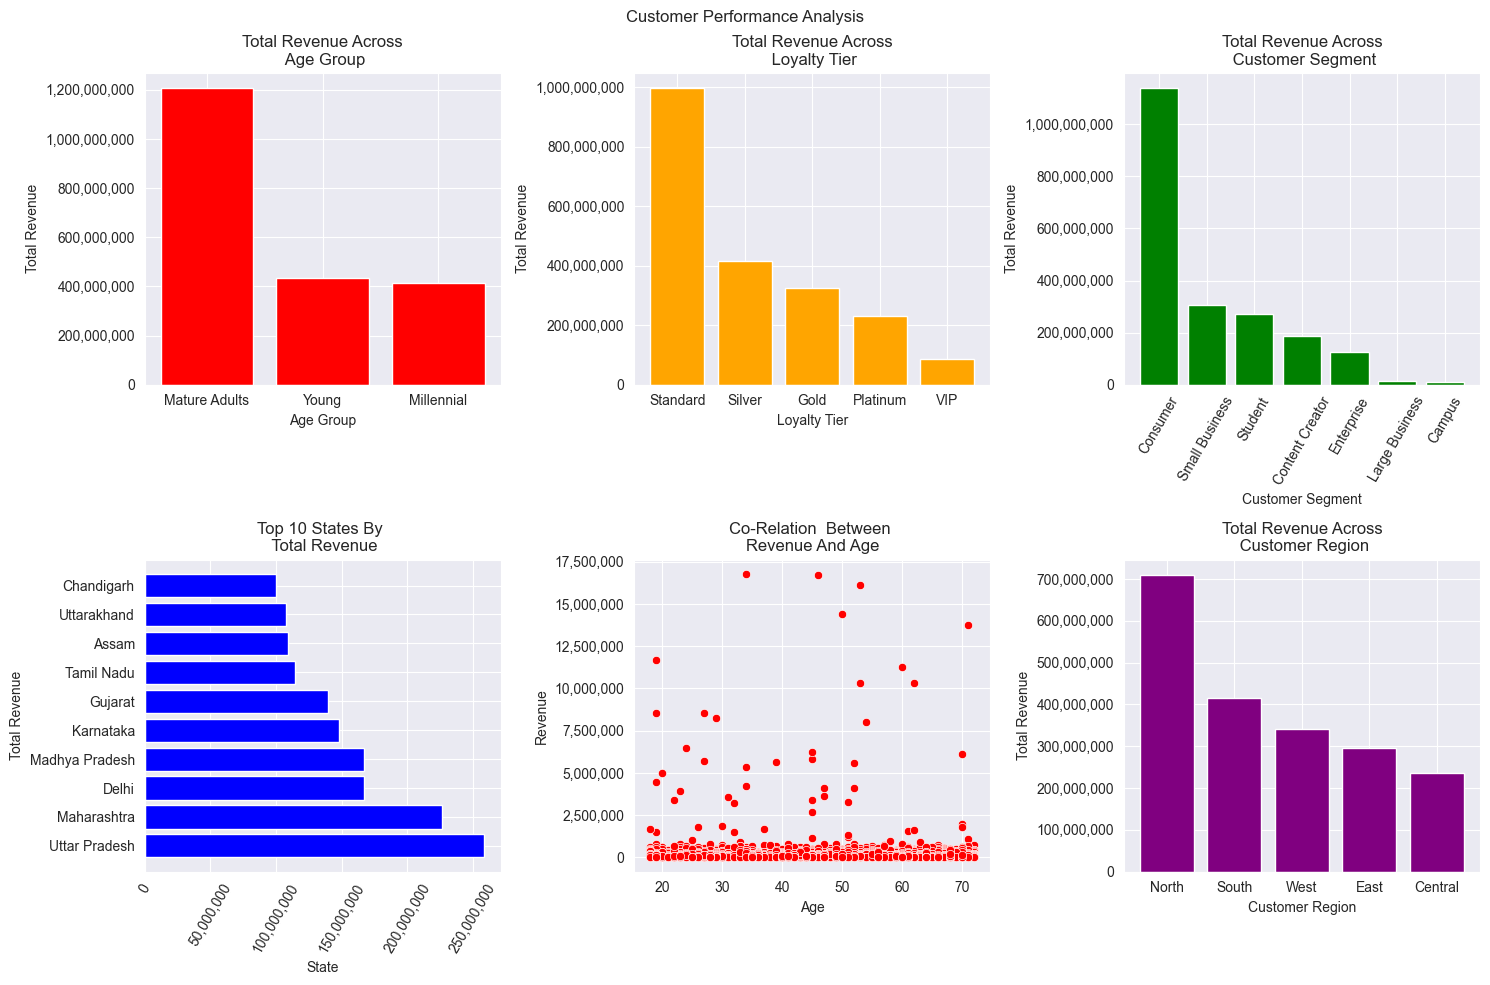

In [513]:
from matplotlib.ticker import FuncFormatter
figure, ax = plt.subplots(2, 3, figsize=(15, 10))

# Chart 1
ax[0,0].bar(age_grp_sale["age_group"], age_grp_sale["total revenue"], color = "red")
ax[0,0].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[0,0].set_title("Total Revenue Across\n Age Group")
ax[0,0].set_xlabel("Age Group")
ax[0,0].set_ylabel("Total Revenue")

#Chart2
ax[0,1].bar(tier_sale["loyalty_tier"], tier_sale["total revenue"], color = "orange")
ax[0,1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[0,1].set_title("Total Revenue Across\n Loyalty Tier")
ax[0,1].set_xlabel("Loyalty Tier")
ax[0,1].set_ylabel("Total Revenue")

#Chart3
ax[0,2].bar(segment_sales["customer_segment"], segment_sales["total revenue"], color = "green")
ax[0,2].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[0,2].set_title("Total Revenue Across\n Customer Segment")
ax[0,2].set_xlabel("Customer Segment")
ax[0,2].set_ylabel("Total Revenue")
ax[0,2].tick_params(axis = "x", rotation = 60)

#Chart4
ax[1,0].barh(cust_state_sale["state"], cust_state_sale["total revenue"], color = "blue")
ax[1,0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[1,0].set_title("Top 10 States By \n Total Revenue")
ax[1,0].set_xlabel("State")
ax[1,0].set_ylabel("Total Revenue")
ax[1,0].tick_params(axis = "x", rotation = 60)

#Chart5
sns.scatterplot(data = cust_sale, x = "age", y = "sales_amount", ax = ax[1,1], color = "red" )
ax[1,1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[1,1].set_title("Co-Relation  Between \nRevenue And Age")
ax[1,1].set_xlabel("Age")
ax[1,1].set_ylabel("Revenue")

#Chart6
ax[1,2].bar(region_sale["region"], region_sale["total revenue"], color = "purple")
ax[1,2].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[1,2].set_title("Total Revenue Across\n Customer Region")
ax[1,2].set_xlabel("Customer Region")
ax[1,2].set_ylabel("Total Revenue")

plt.suptitle("Customer Performance Analysis")

plt.tight_layout()
plt.savefig("Customer Performance Analysis")

- **Revenue Across Age Groups:** Mature Adults contribute the highest total revenue, approximately ₹1.21 billion, followed by Young customers and Millennials. This indicates that Mature Adults are the largest revenue-contributing age segment. However, further analysis of customer counts can help determine whether this is due to a larger customer base or higher spending.

- **Revenue Across Loyalty Tiers:** Standard-tier customers generate the highest total revenue, followed by Silver and Gold. VIP customers contribute the least total revenue, despite belonging to the highest loyalty tier. This suggests that higher loyalty status does not necessarily translate into higher overall revenue contribution.

- **Revenue Across Customer Segments:** Consumer customers contribute the highest revenue by a significant margin, followed by Small Businesses and Students. Large Businesses and Campus customers contribute the least revenue.

- **Top 10 States by Revenue:** Uttar Pradesh generates the highest revenue, followed by Maharashtra. Madhya Pradesh and Delhi are also among the major revenue-contributing states, while Chandigarh records the lowest revenue among the top 10 states.

- **Age vs Revenue Correlation:** The correlation coefficient of approximately -0.003 indicates a negligible negative linear relationship between customer age and sales amount. This suggests that customer age alone is not a meaningful indicator of individual spending behaviour.

- **Revenue Across Regions:** The North region generates the highest total revenue, followed by South and West. Central records the lowest revenue contribution among all five regions.

**Overall Business Observation**

The analysis indicates that Mature Adults, Standard-tier customers, and Consumer customers are major contributors to overall revenue. Geographically, Uttar Pradesh and the North region lead in revenue generation. However, customer age has virtually no linear relationship with individual sales amount, suggesting that other factors may play a more significant role in determining customer spending behaviour.

In [514]:
stor.head()

,store_key,store_name,channel_type,city,state,region,location_type,opening_date,store_status
0,S001,Techsquare Delhi Hub,Retail,Delhi,Delhi,North,Business Park,2018-01-03,Close
1,S002,Techsquare Noida Flagship,Retail,Noida,Uttar Pradesh,North,Express Outlet,2021-06-25,Open
2,S003,Techsquare Gurugram Express,B2b,Gurugram,Haryana,North,Business Park,2018-08-22,Open
3,S004,Techsquare Kanpur Mall,Retail,Kanpur,Uttar Pradesh,North,High Street,2023-07-28,NaN
4,S005,Techsquare Lucknow Mall,Retail,Lucknow,Uttar Pradesh,North,Mall,2021-02-14,Open


**How do different store characteristics influence overall store performance and revenue generation?**

In [515]:
stor_sale = pd.merge(stor, sale, on = "store_key", how = "inner")

In [516]:
stor_sale.head(1)

,store_key,store_name,channel_type,city,state,region,location_type,opening_date,store_status,sales_key,...,quantity_sold,selling_price,discount_percent,product_cost,shipping_cost,tax_percent,sales_amount,total_cost,profit_amount,profit_percent
0,S001,Techsquare Delhi Hub,Retail,Delhi,Delhi,North,Business Park,2018-01-03,Close,L00000079,...,1.00,"23,633.08",5.00,"15,685.79",0.00,18.00,"26,492.68","15,685.79","10,806.89",40.79


In [517]:
pd.options.display.float_format = '{:,.2f}'.format
channel_sale = stor_sale.groupby("channel_type")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending  = False)
channel_sale

,channel_type,total revenue
4,Retail,"1,309,270,469.40"
2,Online,"314,798,966.20"
1,Marketplace,"208,168,397.67"
0,B2b,"115,961,502.21"
3,Partner,"109,752,809.84"


In [518]:
pd.options.display.float_format = '{:,.2f}'.format
loc_type_sale = stor_sale.groupby("location_type")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending  = True)
loc_type_sale

,location_type,total revenue
2,Corporate Portal,"35,627,132.27"
6,Mall,"108,089,537.62"
7,Reseller Partner,"109,752,809.84"
5,High Street,"117,058,933.11"
9,Web Store,"137,992,191.00"
1,Campus Portal,"176,806,775.20"
8,Third-Party Marketplace,"208,168,397.67"
4,Flagship,"245,265,200.88"
3,Express Outlet,"280,574,437.42"
0,Business Park,"638,616,730.31"


In [519]:
pd.options.display.float_format = '{:,.2f}'.format
state_sale = stor_sale.groupby("state")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending  = False).head(10)
state_sale

,state,total revenue
8,Maharashtra,"422,396,012.84"
11,Tamil Nadu,"199,950,292.87"
5,Karnataka,"196,795,732.05"
13,Uttar Pradesh,"190,437,660.63"
3,Gujarat,"176,867,462.76"
2,Delhi,"167,406,528.81"
6,Kerala,"102,276,749.96"
0,Assam,"75,256,133.27"
10,Rajasthan,"74,441,267.07"
4,Haryana,"72,614,635.02"


In [520]:
pd.options.display.float_format = '{:,.2f}'.format
city_sale = stor_sale.groupby("city")["sales_amount"].sum().reset_index(name = "total revenue").sort_values(by = "total revenue", ascending  = False).head(10)
city_sale

,city,total revenue
19,Pune,"235,267,789.71"
1,Bengaluru,"196,795,732.05"
16,Mumbai,"187,012,204.34"
6,Delhi,"167,406,528.81"
4,Chennai,"120,358,103.89"
0,Ahmedabad,"116,321,181.61"
13,Kochi,"102,276,749.96"
17,Nagpur,"80,412,544.33"
5,Coimbatore,"79,592,188.98"
8,Guwahati,"75,256,133.27"


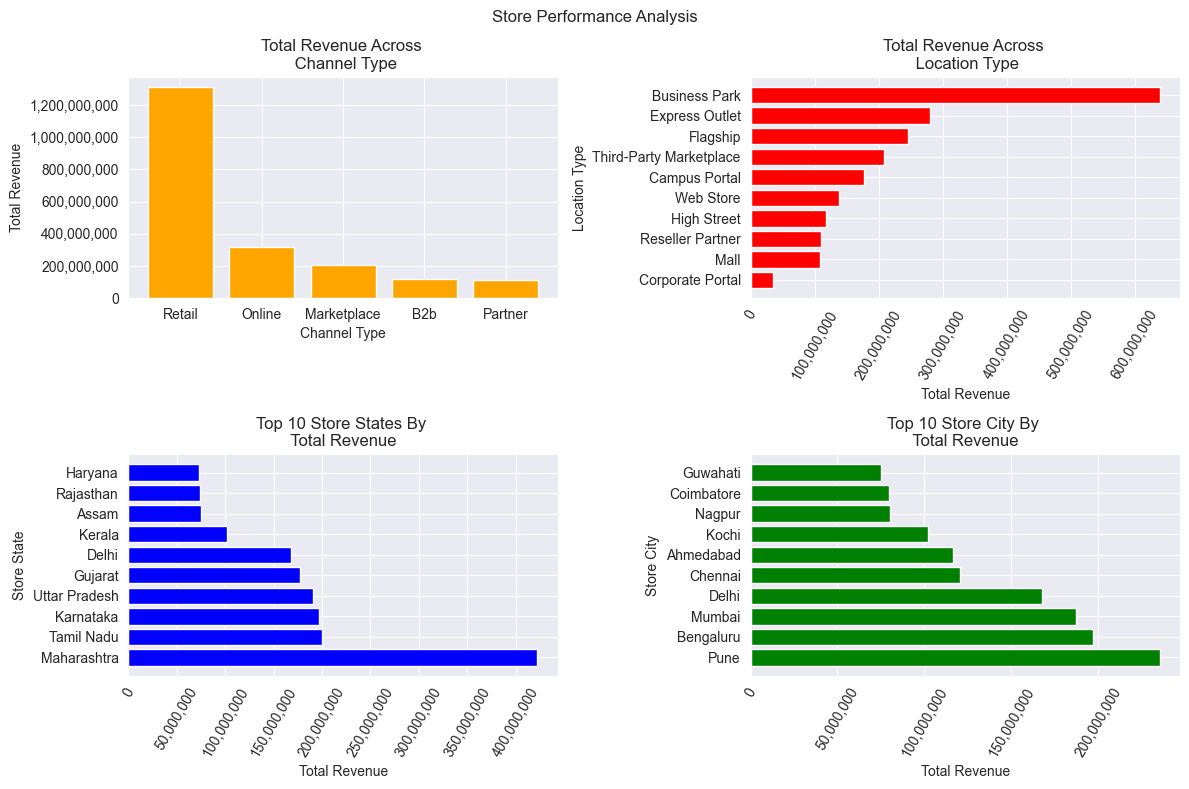

In [521]:
figure, ax = plt.subplots(2,2, figsize = (12,8))

#Chart1
ax[0,0].bar(channel_sale["channel_type"], channel_sale ["total revenue"], color = "orange")
ax[0,0].set_title("Total Revenue Across \n Channel Type")
ax[0,0].set_xlabel("Channel Type")
ax[0,0].set_ylabel("Total Revenue")
ax[0,0].yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))

#Chart2
ax[0,1].barh(loc_type_sale["location_type"], loc_type_sale["total revenue"], color = "red")
ax[0,1].set_title("Total Revenue Across \n Location Type")
ax[0,1].set_ylabel("Location Type")
ax[0,1].set_xlabel("Total Revenue")
ax[0,1].xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[0,1].tick_params(axis = "x", rotation = 60)

#Chart3
ax[1,0].barh(state_sale["state"], state_sale["total revenue"], color = "blue")
ax[1,0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[1,0].tick_params(axis = "x", rotation = 60)
ax[1,0].set_title("Top 10 Store States By \n Total Revenue ")
ax[1,0].set_ylabel("Store State")
ax[1,0].set_xlabel("Total Revenue")

#Chart4
ax[1,1].barh(city_sale["city"], city_sale["total revenue"], color = "Green")
ax[1,1].xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax[1,1].tick_params(axis = "x", rotation = 60)
ax[1,1].set_title("Top 10 Store City By \n Total Revenue ")
ax[1,1].set_ylabel("Store City")
ax[1,1].set_xlabel("Total Revenue")

plt.suptitle("Store Performance Analysis")
plt.tight_layout()
plt.savefig("Store Performance Analysis")


- **Revenue Across Sales Channels:** Retail is the highest revenue-generating channel by a significant margin, followed by Online and Marketplace. B2B and Partner channels contribute comparatively lower revenue.

- **Revenue Across Location Types:** Business Parks generate the highest revenue, followed by Express Outlets and Flagship stores. Corporate Portal locations contribute the least revenue.

- **Top-Performing States:** Maharashtra generates the highest revenue among the top 10 states, followed by Tamil Nadu and Karnataka. Haryana, Rajasthan, and Assam record comparatively lower revenue.

- **Top-Performing Cities:** Pune leads in total revenue, followed by Bengaluru and Mumbai. Delhi also makes a significant contribution, while Guwahati records the lowest revenue among the top 10 cities.

- **Overall Business Observation:** Retail channels, Business Park locations, and stores in Maharashtra and Pune are major revenue contributors. These findings highlight the importance of sales channels and geographical location in overall store revenue performance.

In [522]:
corr_dis_sale = np.corrcoef(sale["discount_percent"], sale["sales_amount"])
corr_dis_sale

array([[ 1., nan],
       [nan, nan]])

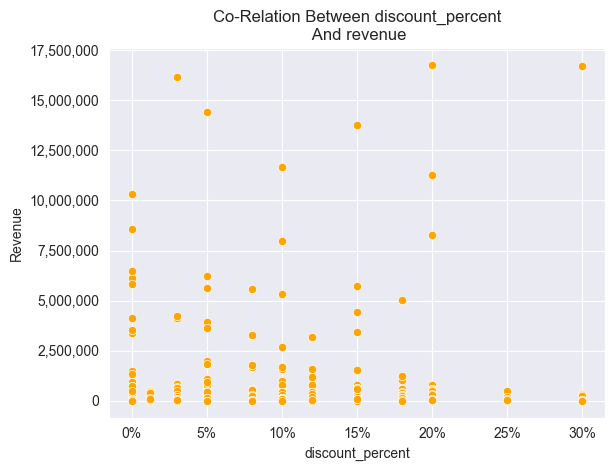

In [524]:
ax =sns.scatterplot(data = sale, x = "discount_percent", y = "sales_amount", color = "orange")
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}')
)
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}%')
)
plt.ylabel("Revenue")
plt.title("Co-Relation Between discount_percent\n And revenue")
plt.savefig("Co-Relation Between discount_percent And revenue")

**Discount vs Sales Correlation:** The correlation coefficient between discount percentage and sales amount is approximately -0.021, indicating a negligible negative linear correlation. This suggests that changes in discount percentage have virtually no linear association with sales amount in the dataset.

In [525]:
total_profit_mon = date_sale.groupby("month_name")["profit_amount"].sum().reset_index(name = "total profit")

C:\Users\Ranu Gupta\AppData\Local\Temp\ipykernel_53368\2787638100.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  total_profit_mon = date_sale.groupby("month_name")["profit_amount"].sum().reset_index(name = "total profit")


In [526]:
total_profit_mon

,month_name,total profit
0,January,"48,351,119.87"
1,February,"38,166,173.54"
2,March,"48,742,061.72"
3,April,"52,990,235.74"
4,May,"48,366,852.76"
5,June,"49,567,657.58"
6,July,"44,825,454.39"
7,August,"43,957,558.96"
8,September,"44,503,157.25"
9,October,"53,520,086.53"


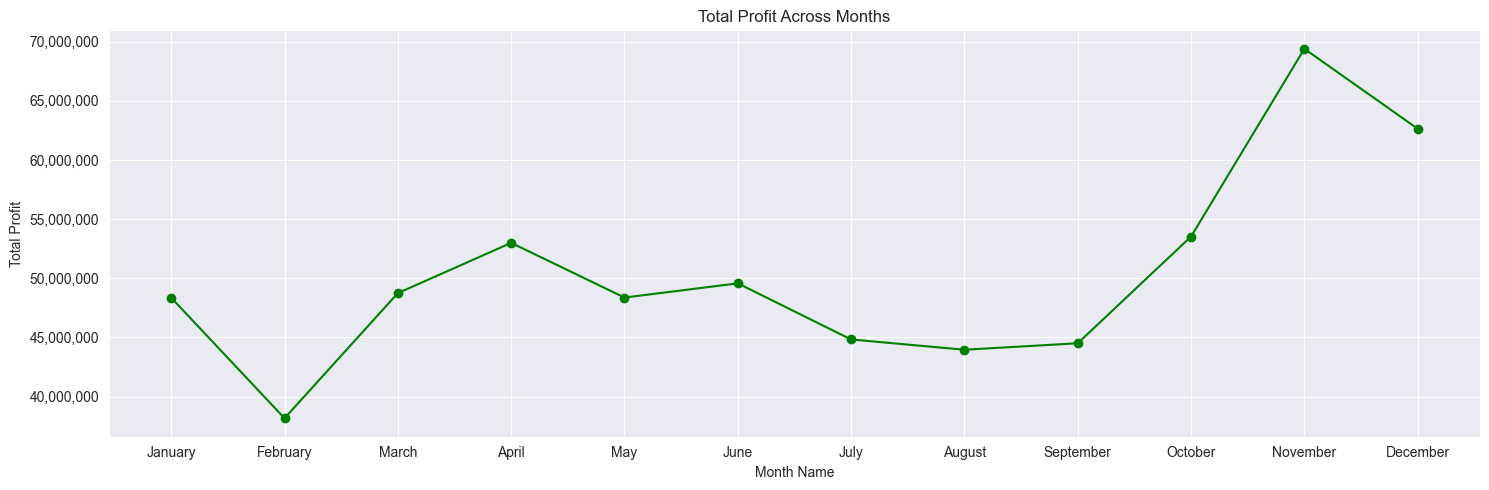

In [527]:
plt.figure(figsize=(15, 5))

ax = plt.gca()

plt.plot(
    total_profit_mon["month_name"],
    total_profit_mon["total profit"],
    color="green",
    marker="o"
)

ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:,.0f}')
)

plt.xlabel("Month Name")
plt.ylabel("Total Profit")
plt.title("Total Profit Across Months")

plt.tight_layout()
plt.savefig("Total Profit Across Months")

- **November generated the highest total profit**, reaching approximately 69 million, followed by December at around 63 million.
- **February recorded the lowest total profit**, at approximately 38 million, followed by a recovery in March and April.
- Profit remained relatively stable between May and September, fluctuating between approximately 44 million and 50 million.
- **A significant increase in profitability occurred from October to November**, indicating a strong improvement in business performance towards the end of the year.

#### **Exporting the cleaned csv files for Power BI Dashboard**

In [528]:
cust.to_csv("Cleaned Customers.csv")
stor.to_csv("Cleaned Stores.csv")
date.to_csv("Cleaned Dates.csv")
prod.to_csv("Cleaned Products.csv")
sale.to_csv("Cleaned Sales.csv")